
Dataset: https://www.andyreiter.com/datasets/ 
https://www.usnews.com/best-colleges/rankings/national-universities 
https://nces.ed.gov/ipeds/datacenter/DataFiles.aspx?year=2024&sid=b6a4d888-22e4-45eb-b568-189d139610c2&rtid=1 (1st row dictionary and data)





In [1]:
#data 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

UniversityRankings = pd.read_csv("UniversityRankings.csv")

UniversityRankings = UniversityRankings[['University Name','IPEDS','2027', '2026', '2025', '2024', '2023', '2022']]

Top50 = UniversityRankings[UniversityRankings['2022'] <= 50].copy()

#There are 6 schools tied for 49 in 2022 so top 54 schools were taken into account 

#Converts all numbers to integers
years = ['2022', '2023', '2024', '2025', '2026', '2027']
Top50[years] = Top50[years].apply(
    pd.to_numeric, errors='coerce'
).astype('Int64')


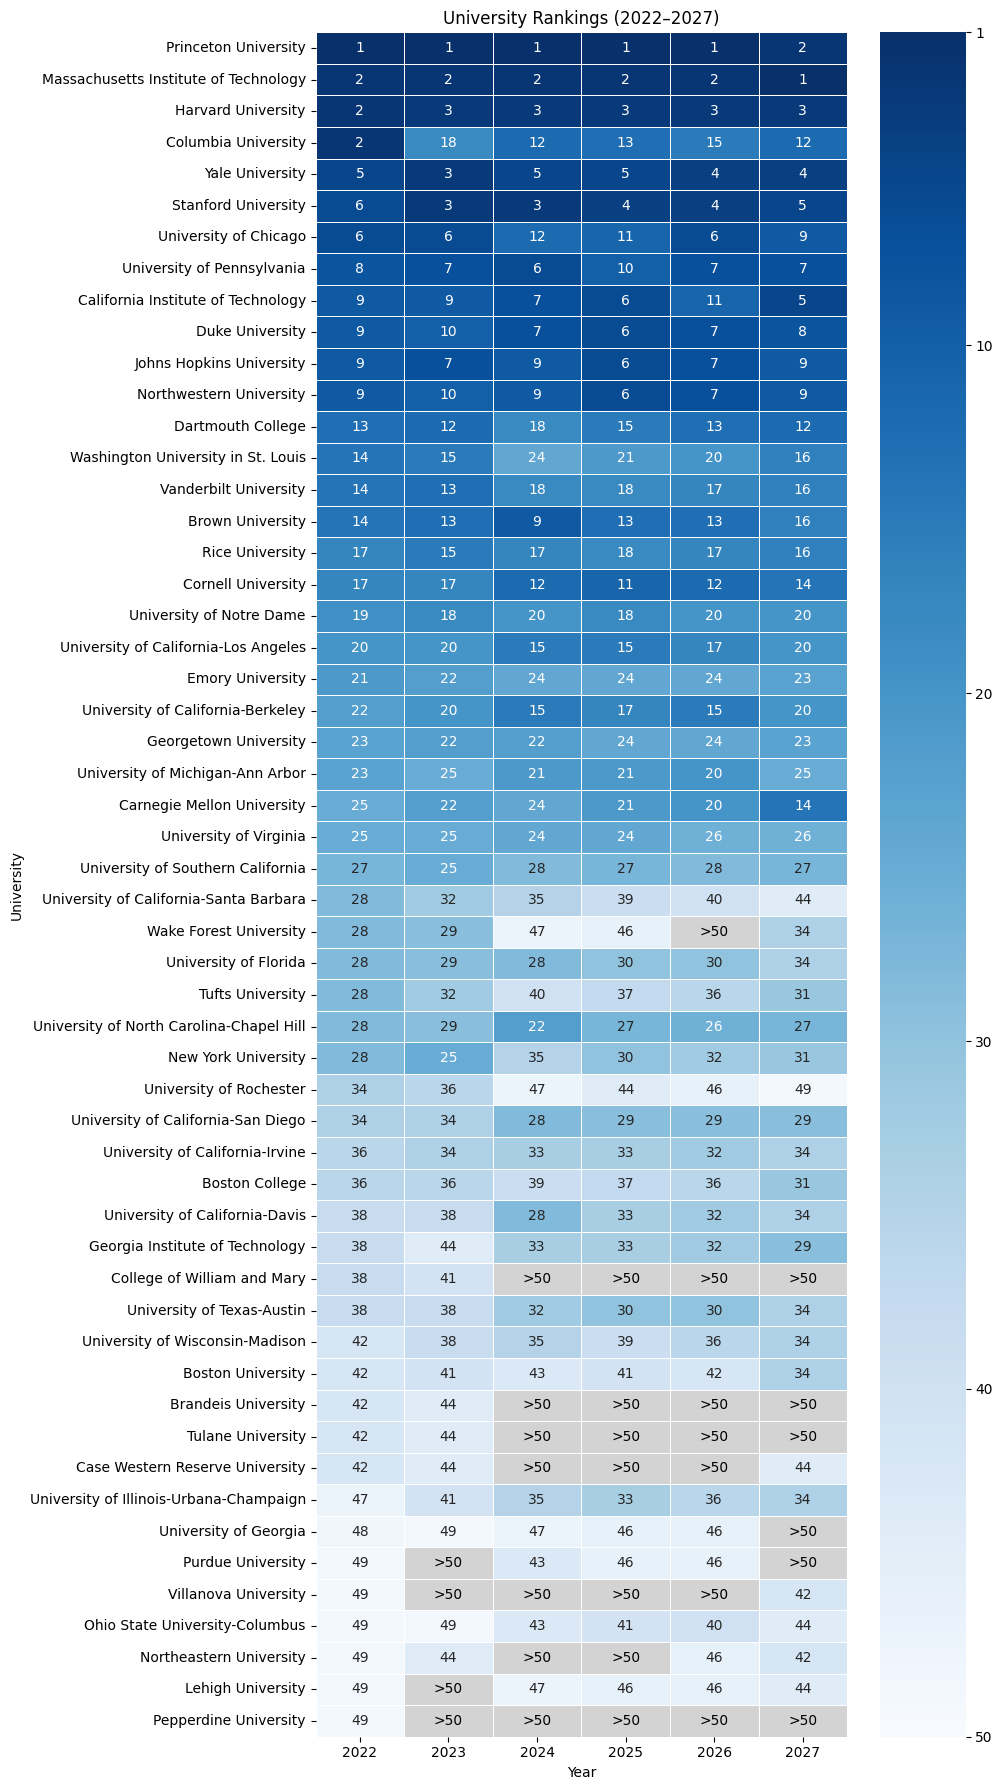

In [2]:
#top 50 universities highlighted 
heatmap_data = Top50[['University Name'] + years].copy()
heatmap_data = heatmap_data.sort_values('2022')
heatmap_data = heatmap_data.set_index('University Name')
heatmap_data = heatmap_data.astype(float)

#Filters >50
labels = heatmap_data.copy()
labels = labels.map(lambda x: '>50' if x > 50 else str(int(x)) if pd.notna(x) else '')
heatmap_colors = heatmap_data.where(heatmap_data <= 50)

plt.figure(figsize=(10, 18))
ax = sns.heatmap(
    heatmap_colors,
    annot=labels.to_numpy(),
    fmt='',
    cmap='Blues_r',
    vmin=1,
    vmax=50,
    linewidths=0.5,
)

#flips legend upsidown (1 on top)
cbar = ax.collections[0].colorbar
cbar.ax.invert_yaxis()
cbar.set_ticks([1, 10, 20, 30, 40, 50])

ax.set_facecolor('lightgrey')
for i in range(len(heatmap_data)):
    for j in range(len(heatmap_data.columns)):
        if heatmap_data.iloc[i, j] > 50:
            ax.text(j + 0.5, i + 0.5, '>50',
                    ha='center', va='center', color='black')
            
plt.title('University Rankings (2022–2027)', fontsize=12)
plt.xlabel('Year')
plt.ylabel('University')
plt.yticks(rotation=0)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()







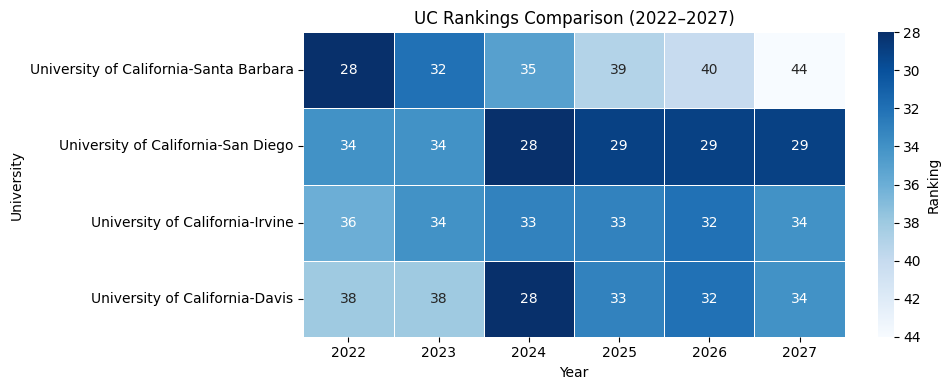

In [3]:
# UCSB, UCI, UCSD, and UCD highlighted 
UC_data = UniversityRankings[
    UniversityRankings['University Name'].str.contains(
        'University of California', case=False, na=False) &
    UniversityRankings['University Name'].str.contains(
        'Santa Barbara|Irvine|San Diego|Davis', case=False, na=False)
].copy()

UC_heatmap = UC_data.set_index('University Name')[years]
UC_heatmap = UC_heatmap.apply(pd.to_numeric, errors='coerce').astype(float)
UC_heatmap = UC_heatmap.sort_values('2022')

plt.figure(figsize=(10, 4))
sec = sns.heatmap(
    UC_heatmap,
    annot=True,
    fmt='.0f',
    cmap='Blues_r',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Ranking'}
)

cbar = sec.collections[0].colorbar
cbar.ax.invert_yaxis()

plt.title('UC Rankings Comparison (2022–2027)')
plt.xlabel('Year')
plt.ylabel('University')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
ipeds = pd.read_csv("hd2024.csv")

#mannual search done to link private and public schools 
#discovered it was sorted in "control"

# Reload the original data to remove duplicate columns
UniversityRankings = pd.read_csv("UniversityRankings.csv")

ipeds = ipeds[['UNITID', 'INSTNM', 'CONTROL']].copy()

# Classify universities
ipeds['Type'] = ipeds['CONTROL'].map({
    1: 'Public',
    2: 'Private Nonprofit',
    3: 'Private For-Profit'
})

# Merge with all universities
UniversityRankings = UniversityRankings.merge(
    ipeds[['UNITID', 'Type']],
    left_on='IPEDS',
    right_on='UNITID',
    how='left',
    validate='many_to_one'
)


                       mean  median  count
Type                                      
Private Nonprofit  1.694444     0.0     36
Public            -0.222222    -1.5     18


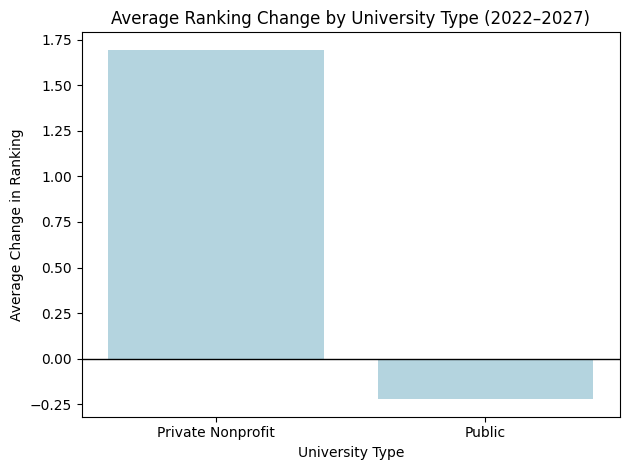

In [17]:
#private and public in top 50 changes 
Top50 = UniversityRankings[UniversityRankings['2022'] <= 50].copy()

Top50['2022'] = pd.to_numeric(Top50['2022'], errors='coerce')
Top50['2027'] = pd.to_numeric(Top50['2027'], errors='coerce')
Top50['Ranking_Change'] = Top50['2027'] - Top50['2022']

comparison = Top50.groupby('Type')['Ranking_Change'].agg(
    ['mean', 'median', 'count']
)

print(comparison)

avg_change = Top50.groupby('Type', as_index=False)['Ranking_Change'].mean()

sns.barplot(
    data=avg_change,
    x='Type',
    y='Ranking_Change',
    color='lightblue'
)
plt.axhline(0, color='black', linewidth=1)
plt.title('Average Ranking Change by University Type (2022–2027)')
plt.xlabel('University Type')
plt.ylabel('Average Change in Ranking')
plt.tight_layout()
plt.show()

                       mean  median  count
Type                                      
Private Nonprofit  3.958333     1.5     72
Public            -4.455882    -4.0     68


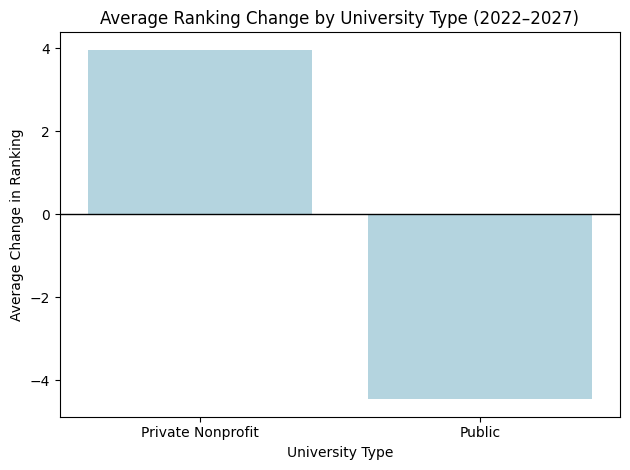

In [18]:
#private and public changes in all data 
UR = UniversityRankings.copy()

UR['2022'] = pd.to_numeric(UR['2022'], errors='coerce')
UR['2027'] = pd.to_numeric(UR['2027'], errors='coerce')
UR['Ranking_Change'] = UR['2027'] - UR['2022']

comparison2 = UR.groupby('Type')['Ranking_Change'].agg(
    ['mean', 'median', 'count']
)

print(comparison2)

avg_change2 = UR.groupby('Type', as_index=False)['Ranking_Change'].mean()

sns.barplot(
    data=avg_change2,
    x='Type',
    y='Ranking_Change',
    color='lightblue'
)
plt.axhline(0, color='black', linewidth=1)
plt.title('Average Ranking Change by University Type (2022–2027)')
plt.xlabel('University Type')
plt.ylabel('Average Change in Ranking')
plt.tight_layout()
plt.show()